In [1]:
import sys
sys.path.insert(0, "/Users/ashwanishah/Desktop/AQI/MODEL/Utility_fun")
import aqi_utils as U


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.4 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/opt/anaconda3/lib/python3.12/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/opt/anaconda3/lib/python3.12/site-packages/traitlets/config/application.py", line 1080, in launch_instance
    app.start()
  File "/opt/anaconda3/lib/python3.12/site-packages/ipykernel/kernelapp.py", line 768, in start
    self.io_loop.start()
  File "/opt/anaconda3/lib/python3.12/site-

AttributeError: _ARRAY_API not found


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.4 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/opt/anaconda3/lib/python3.12/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/opt/anaconda3/lib/python3.12/site-packages/traitlets/config/application.py", line 1080, in launch_instance
    app.start()
  File "/opt/anaconda3/lib/python3.12/site-packages/ipykernel/kernelapp.py", line 768, in start
    self.io_loop.start()
  File "/opt/anaconda3/lib/python3.12/site-

ImportError: 
A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.4 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.



In [2]:
 # ===== ITO – Part A: Setup, load and tidy =====
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import aqi_utils as U

STATION  = "Punjab_Ludhiana"
DATA_DIR = "/Users/ashwanishah/Desktop/AQI/DATASETS/Punjab-Ludhiana"                 
LAT, LON =  30.90, 75.85          
FIG = "figures_ludhiana"
os.makedirs(FIG, exist_ok=True)

# 1. load all files
raw = U.load_cpcb(DATA_DIR)

# 2. tidy: drop empty columns, remove duplicate hours, fill in missing hours
n_before = len(raw)
raw = U.tidy(raw)
print("\nShape:", raw.shape, "| from", raw.index.min(), "to", raw.index.max())
print("Hours in files:", n_before, "| full hourly timeline:", len(raw))

# 3. missing % per column
print("\nMissing % per column:")
print((raw.isna().mean() * 100).round(1).sort_values())

/opt/anaconda3/lib/python3.12/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/opt/anaconda3/lib/python3.12/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/opt/anaconda3/lib/python3.12/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/opt/anaconda3/lib/python3.12/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


files: ['Ludhiana-2023.xlsx', 'Ludhiana-2024.xlsx', 'Ludhiana-2025.xlsx', 'Ludhiana-2026-sept.xlsx']

Shape: (32832, 15) | from 2023-01-01 00:00:00 to 2026-09-29 23:00:00
Hours in files: 32760 | full hourly timeline: 32832

Missing % per column:
RH          4.1
WD          4.1
WS          4.1
SR          4.2
PM2.5       4.4
SO2         4.7
TOLUENE     5.1
PM10        5.2
BENZENE     5.2
CO          6.2
RF         18.8
NO2        28.0
NO         28.1
NH3        28.1
AT         98.0
dtype: float64


Removed by cleaning (hours) and missing % after:
         negative  flatline  stuck_0.1  missing_%_now
PM2.5           0        20          0            4.4
PM10            0        20          0            5.2
NO              0       285          0           28.9
NO2             0       288          1           28.9
NH3             0       276          0           28.9
SO2             0         0          0            4.7
CO              0       154          0            6.6
BENZENE         0     24262          0           79.1
TOLUENE         0     24780          0           80.6


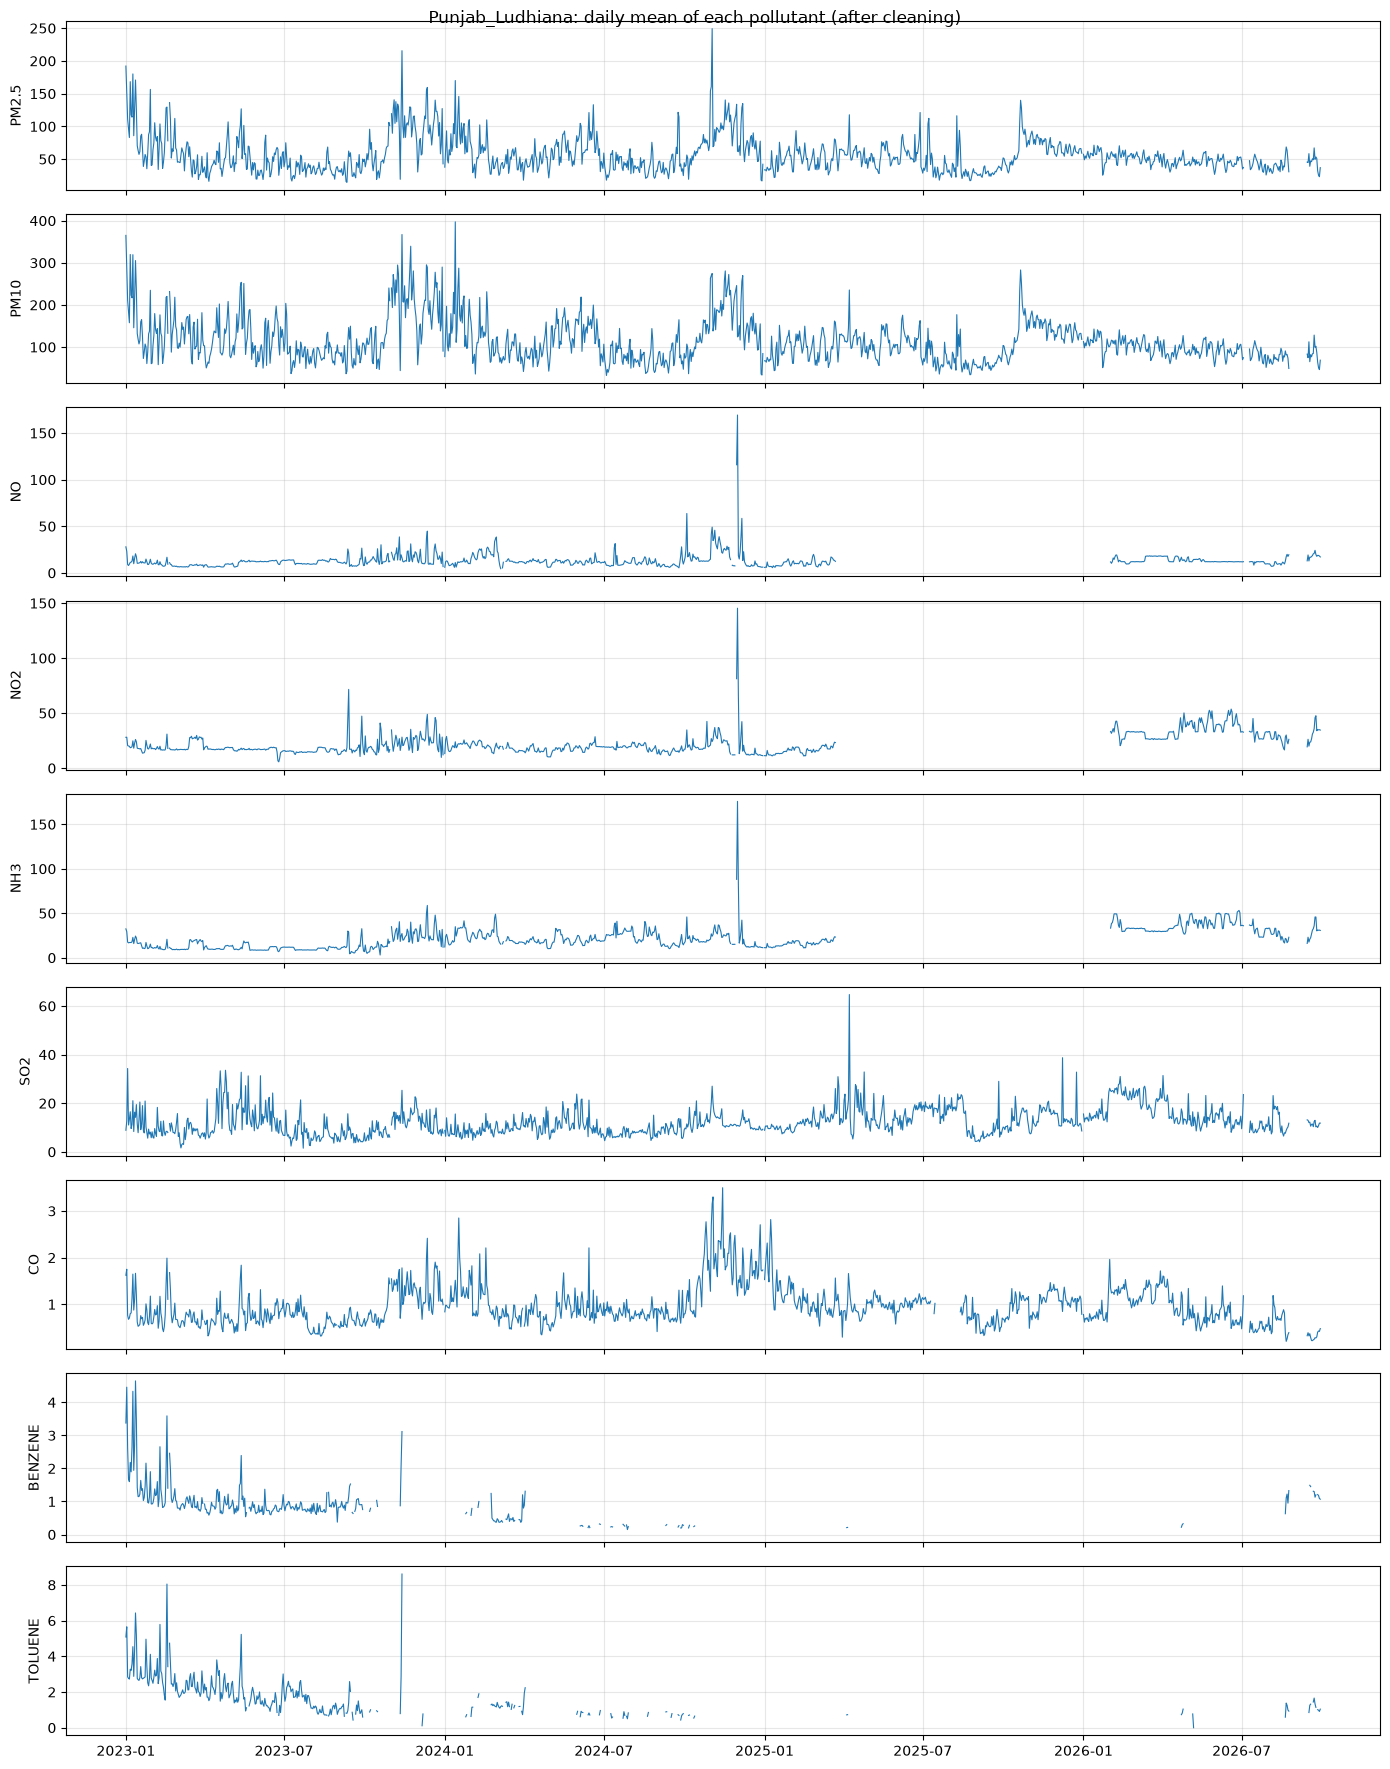

In [3]:
# ===== ITO – Part B: Clean and check the sensors =====
data, qc = U.clean_pollutants(raw)
print("Removed by cleaning (hours) and missing % after:")
print(qc)

# daily mean of each pollutant, 2023–2026
POLS = [p for p in U.ALL_POLS if p in data.columns]
daily = data[POLS].resample("D").mean()

fig, axes = plt.subplots(len(POLS), 1, figsize=(14, 2.0 * len(POLS)), sharex=True)
for ax, p in zip(axes, POLS):
    ax.plot(daily.index, daily[p], lw=0.8)
    ax.set_ylabel(p); ax.grid(alpha=0.3)
plt.suptitle(f"{STATION}: daily mean of each pollutant (after cleaning)")
plt.tight_layout(); plt.savefig(f"{FIG}/pollutants_daily.png", dpi=200); plt.show()

In [4]:
# valid daily values (%) after QC: day counts if >= 16 valid hours
SEVEN = ["PM2.5", "PM10", "NO2", "SO2", "NH3", "CO", "O3"]
have = [p for p in SEVEN if p in data.columns]
print("not in data:", [p for p in SEVEN if p not in have])

days = pd.date_range("2023-01-01", "2026-09-30", freq="D")
valid_hours = data[have].notna().resample("D").sum().reindex(days, fill_value=0)
print(((valid_hours >= 16).mean() * 100).round(1))

not in data: ['O3']
PM2.5    96.6
PM10     96.1
NO2      71.1
SO2      96.7
NH3      71.1
CO       94.0
dtype: float64


In [5]:
d = raw["PM2.5"].resample("D").mean()
for start, end in [("2023-11-01", "2024-02-29"), ("2024-11-01", "2025-02-28"), ("2025-11-01", "2026-02-28")]:
    print(f"Winter {start[:4]}–{end[:4]}: mean PM2.5 {d[start:end].mean():.0f} | "
          f"typical day-to-day change {d[start:end].diff().abs().median():.1f} µg/m³")

Winter 2023–2024: mean PM2.5 85 | typical day-to-day change 17.9 µg/m³
Winter 2024–2025: mean PM2.5 69 | typical day-to-day change 9.9 µg/m³
Winter 2025–2026: mean PM2.5 63 | typical day-to-day change 5.2 µg/m³


In [6]:
# ===== Ludhiana – Part B (decision) =====
DROPPED = {
    "NO":  "near-flat plateaus 2023–mid 2024, shared spike Dec 2024, missing Apr 2025–Jan 2026",
    "NO2": "near-flat plateaus 2023–mid 2024, shared spike Dec 2024, missing Apr 2025–Jan 2026",
    "NH3": "near-flat plateaus 2023–mid 2024, shared spike Dec 2024, missing Apr 2025–Jan 2026",
}
data = data.drop(columns=[c for c in DROPPED if c in data.columns])
POLS_ITO = [p for p in U.AQI_POLS_ALL if p in data.columns]
print("Kept pollutants:", POLS_ITO)
print("Flag: PM2.5/PM10 unusually smooth from about Oct 2025 (possible sensor/processing change)")

Kept pollutants: ['PM2.5', 'PM10', 'SO2', 'CO']
Flag: PM2.5/PM10 unusually smooth from about Oct 2025 (possible sensor/processing change)


In [7]:
# ===== ITO – Part C: ERA5 weather =====
met = U.get_era5(LAT, LON,
                 str(data.index.min().date()), str(data.index.max().date()),
                 cache_file="era5_punjab_lu.csv")
print("ERA5:", met.shape, met.index.min(), "to", met.index.max())
print("Missing %:", (met.isna().mean() * 100).round(1).to_dict())

data = U.use_era5(data, met)
print("\nColumns now:", list(data.columns))
print("Shape:", data.shape)

ERA5: (32832, 8) 2023-01-01 00:00:00 to 2026-09-29 23:00:00
Missing %: {'temperature_2m': 0.0, 'relative_humidity_2m': 0.0, 'shortwave_radiation': 0.0, 'precipitation': 0.0, 'wind_speed_10m': 0.0, 'wind_direction_10m': 0.0, 'surface_pressure': 0.0, 'cloud_cover': 0.0}

Columns now: ['PM2.5', 'PM10', 'SO2', 'CO', 'BENZENE', 'TOLUENE', 'AT', 'RH', 'SR', 'RF', 'wind_speed_10m', 'WD', 'surface_pressure', 'cloud_cover']
Shape: (32832, 14)


In [8]:
# ===== ITO – Part D: Daily values, AQI, features =====
Y = U.make_daily_conc(data, POLS_ITO)                     # daily concentrations (targets)
X = U.build_features(data, Y, POLS_ITO)                   # inputs
pers = pd.DataFrame({p: X[f"{p}_lag1"] for p in POLS_ITO})  # persistence

aqi_true = U.compute_aqi(Y, POLS_ITO)
aqi_cat  = U.to_cat(aqi_true)
print("X:", X.shape, "| Y:", Y.shape)
print("Days with an AQI:", aqi_true.notna().sum(), "of", len(aqi_true))

# categories in each period
check = pd.DataFrame({s: aqi_cat[U.in_period(aqi_cat.index, s) & aqi_true.notna()].value_counts().reindex(U.CATS)
                      for s in U.SPLITS}).fillna(0).astype(int)
check.loc["total days"] = check.sum()
print("\nAQI categories per period:")
print(check)

# which pollutant decides the AQI
sub = pd.DataFrame({p: U.sub_index(Y[p], p) for p in POLS_ITO})
print("\nWhich pollutant decides the AQI (% of days):")
print((sub[aqi_true.notna()].idxmax(axis=1).value_counts(normalize=True) * 100).round(1))

X: (1368, 29) | Y: (1368, 4)
Days with an AQI: 1323 of 1368

AQI categories per period:
              train  val  test  test2
Good             19    0    13      1
Satisfactory    252   12   145    136
Moderate        271   49   188    103
Poor             59   21    11      0
Very Poor        31    9     3      0
Severe            0    0     0      0
total days      632   91   360    240

Which pollutant decides the AQI (% of days):
PM10     65.3
PM2.5    26.5
CO        8.2
Name: proportion, dtype: float64


In [9]:
# ===== ITO – Part E: Own model vs persistence (N2) =====
with open("/Users/ashwanishah/Desktop/AQI/MODEL/FINAL-MODEL-WORKING/delhi_saved/final_params.json") as f:   # adjust path if needed
    FINAL_PARAMS = json.load(f)

FINAL_MODELS = ["Lasso", "ExtraTrees", "LightGBM", "HistGB"]
SEEDS = [0, 1, 2, 3, 4]
fit   = X.index <= "2024-12-31"
test  = U.in_period(X.index, "test")
test2 = U.in_period(X.index, "test2")

own_preds = {}
for name in FINAL_MODELS:
    own_preds[name] = [U.forecast(X[fit], Y[fit], X, POLS_ITO, name, {**FINAL_PARAMS[name], "random_state": s})
                       for s in SEEDS]
    print("done:", name)

for label, days in [("Test 2025", test), ("Test Jan–Sep 2026", test2)]:
    rows = [{"model": "Persistence", **U.scores(pers, days, Y, pers, POLS_ITO)}]
    for name in FINAL_MODELS:
        sc = pd.DataFrame([U.scores(p, days, Y, pers, POLS_ITO) for p in own_preds[name]])
        rows.append({"model": name, "days": sc.days.iloc[0],
                     "accuracy": round(sc.accuracy.mean(), 3), "macro_F1": round(sc.macro_F1.mean(), 3),
                     "PM2.5_skill": round(sc["PM2.5_skill"].mean(), 3), "PM10_skill": round(sc["PM10_skill"].mean(), 3)})
    print(f"\n{STATION} – {label} (own model, mean of 5 seeds):")
    print(pd.DataFrame(rows).to_string(index=False))

    ci_rows = [{"model": name, **U.gain_ci(own_preds[name], days, Y, pers, POLS_ITO)} for name in FINAL_MODELS]
    print(f"\nGain over persistence, {label}:")
    print(pd.DataFrame(ci_rows).to_string(index=False))

done: Lasso
done: ExtraTrees
done: LightGBM
done: HistGB

Punjab_Ludhiana – Test 2025 (own model, mean of 5 seeds):
      model  days  accuracy  macro_F1  PM2.5_skill  PM10_skill
Persistence   355     0.724     0.468        0.000       0.000
      Lasso   355     0.772     0.421        0.032       0.031
 ExtraTrees   355     0.750     0.400       -0.072      -0.022
   LightGBM   355     0.707     0.350       -0.140      -0.338
     HistGB   355     0.732     0.340       -0.212      -0.272

Gain over persistence, Test 2025:
     model  days  acc_gain    acc_gain_95CI  F1_gain     F1_gain_95CI  P(F1_gain>0)
     Lasso   355     0.048 [+0.008, +0.090]   -0.048 [-0.135, +0.057]         0.173
ExtraTrees   355     0.026 [-0.005, +0.064]   -0.068 [-0.153, +0.072]         0.163
  LightGBM   355    -0.017 [-0.058, +0.024]   -0.118 [-0.202, +0.014]         0.042
    HistGB   355     0.008 [-0.042, +0.054]   -0.129 [-0.215, +0.005]         0.035

Punjab_Ludhiana – Test Jan–Sep 2026 (own model, me

In [10]:
# ===== ITO – Part F: Leaky vs honest classifier (N1) =====
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

def rf_clf():
    return Pipeline([("fill", SimpleImputer(strategy="median")),
                     ("model", RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1))])

y_cls  = aqi_cat
has    = aqi_true.notna()
X_leak = Y.join(X[U.WEATHER_COLS + U.CALENDAR_COLS])          # TODAY's pollutants + weather + calendar

leaky  = rf_clf().fit(X_leak[fit & has], y_cls[fit & has])
honest = rf_clf().fit(X[fit & has],      y_cls[fit & has])

# same test days for every method
a_pers = U.compute_aqi(pers, POLS_ITO)
a_ours = U.compute_aqi(own_preds["ExtraTrees"][0], POLS_ITO)
days = X.index[test & has & a_pers.notna() & a_ours.notna()]

methods = {"Leaky classifier (same-day pollutants)": leaky.predict(X_leak.loc[days]),
           "CPCB formula on same-day values":        y_cls[days].values,
           "Persistence":                            U.to_cat(a_pers[days]).values,
           "Honest direct classifier":               honest.predict(X.loc[days]),
           "Our route: ExtraTrees + CPCB formula":   U.to_cat(a_ours[days]).values}
rows = [{"method": m, "accuracy": round(accuracy_score(y_cls[days], p), 3),
         "macro_F1": round(U.macro_f1(y_cls[days].values, p), 3)} for m, p in methods.items()]
print(f"{STATION} – test 2025, {len(days)} days:")
print(pd.DataFrame(rows).to_string(index=False))

# where are the leaky model's mistakes?
wrong = methods["Leaky classifier (same-day pollutants)"] != y_cls[days].values
dist = aqi_true[days].apply(lambda a: np.abs(np.array([50, 100, 200, 300, 400]) - a).min())
print(f"\nLeaky mistakes: {wrong.sum()} | median distance to boundary: wrong {dist[wrong].median():.1f}, "
      f"correct {dist[~wrong].median():.1f} | within 15 points: {(dist[wrong] <= 15).mean():.0%}")

Punjab_Ludhiana – test 2025, 355 days:
                                method  accuracy  macro_F1
Leaky classifier (same-day pollutants)     0.977     0.877
       CPCB formula on same-day values     1.000     1.000
                           Persistence     0.724     0.468
              Honest direct classifier     0.775     0.425
  Our route: ExtraTrees + CPCB formula     0.769     0.420

Leaky mistakes: 8 | median distance to boundary: wrong 3.8, correct 14.2 | within 15 points: 88%


In [11]:
import importlib; importlib.reload(U)

SUMMARY_DIR = "/Users/ashwanishah/Desktop/AQI/MODEL/summary"
U.leak_tests(obs_cat   = y_cls[days].values,
             leaky_cat = methods["Leaky classifier (same-day pollutants)"],
             our_cat   = methods["Our route: ExtraTrees + CPCB formula"],
             obs_aqi   = aqi_true[days],
             station   = STATION,
             out_dir   = SUMMARY_DIR)

Punjab_Ludhiana: errors n=8 | boundary Mann–Whitney p = 0.0055 | McNemar leaky vs day-ahead p = 1.06e-22


{'station': 'Punjab_Ludhiana',
 'n_errors': 8,
 'p_boundary': np.float64(0.0054557896382453844),
 'p_mcnemar': np.float64(1.0587911840678754e-22)}

In [12]:
# ===== ITO – Part G: Transfer from Delhi (N3) + 5-pollutant check at Delhi =====
SAVE = "/Users/ashwanishah/Desktop/AQI/MODEL/FINAL-MODEL-WORKING/delhi_saved"          # adjust if needed
Xd = pd.read_csv(f"{SAVE}/delhi_X.csv", index_col=0, parse_dates=True)
Yd = pd.read_csv(f"{SAVE}/delhi_Y.csv", index_col=0, parse_dates=True)

POLS_T = [p for p in POLS_ITO if p in Yd.columns]                 # pollutants both stations have
FEATS  = [c for c in X.columns if c in Xd.columns]                # inputs both stations have
print("Shared pollutants:", POLS_T)
print("Shared inputs:", len(FEATS), "| ITO inputs missing in Delhi:", [c for c in X.columns if c not in Xd.columns])

ET    = FINAL_PARAMS["ExtraTrees"]
d_fit = Xd.index <= "2024-12-31"
LOCAL = {1: "2024-12-01", 2: "2024-11-01", 3: "2024-10-01"}
W     = 10                                                        # weight of local rows

def train_predict(X_tr, Y_tr, X_pred):
    return [U.forecast(X_tr, Y_tr, X_pred, POLS_T, "ExtraTrees", {**ET, "random_state": s}) for s in SEEDS]

# ---------- 1. transfer to ITO ----------
setups = {"Own ITO model (ITO 2023–24)": [p[POLS_T] for p in own_preds["ExtraTrees"]],
          "Zero-shot (Delhi only)":       train_predict(Xd.loc[d_fit, FEATS], Yd.loc[d_fit, POLS_T], X[FEATS])}
for k, start in LOCAL.items():
    lm = (X.index >= start) & (X.index <= "2024-12-31")
    X_tr = pd.concat([Xd.loc[d_fit, FEATS]] + [X.loc[lm, FEATS]] * W)
    Y_tr = pd.concat([Yd.loc[d_fit, POLS_T]] + [Y.loc[lm, POLS_T]] * W)
    setups[f"Few-shot: Delhi + {k} month(s) of ITO"] = train_predict(X_tr, Y_tr, X[FEATS])
    print("done: few-shot", k)

rows = [{"setup": "Persistence", **U.scores(pers, test, Y, pers, POLS_T)}]
for name, preds in setups.items():
    sc = pd.DataFrame([U.scores(p, test, Y, pers, POLS_T) for p in preds])
    ci = U.gain_ci(preds, test, Y, pers, POLS_T)
    rows.append({"setup": name, "days": sc.days.iloc[0],
                 "accuracy": round(sc.accuracy.mean(), 3), "macro_F1": round(sc.macro_F1.mean(), 3),
                 "PM2.5_skill": round(sc["PM2.5_skill"].mean(), 3), "PM10_skill": round(sc["PM10_skill"].mean(), 3),
                 "acc_gain_95CI": ci["acc_gain_95CI"], "F1_gain_95CI": ci["F1_gain_95CI"]})
transfer_ito = pd.DataFrame(rows)
print(f"\nTransfer Delhi -> {STATION}, test 2025:")
print(transfer_ito.to_string(index=False))

# ---------- 2. check: Delhi's own 2025 with only these 5 pollutants ----------
pers_d = pd.DataFrame({p: Xd[f"{p}_lag1"] for p in POLS_T})
d_test = U.in_period(Xd.index, "test")
d5 = train_predict(Xd.loc[d_fit, FEATS], Yd.loc[d_fit, POLS_T], Xd[FEATS])
sc = pd.DataFrame([U.scores(p, d_test, Yd, pers_d, POLS_T) for p in d5])
ci = U.gain_ci(d5, d_test, Yd, pers_d, POLS_T)
print("\nCheck – R K Puram 2025 with only the 5 shared pollutants (ExtraTrees):")
print(f"persistence acc {U.scores(pers_d, d_test, Yd, pers_d, POLS_T)['accuracy']} | "
      f"model acc {sc.accuracy.mean():.3f} | acc gain {ci['acc_gain']:+.3f} {ci['acc_gain_95CI']} | "
      f"PM2.5 skill {sc['PM2.5_skill'].mean():.3f}")

Shared pollutants: ['PM2.5', 'PM10', 'SO2', 'CO']
Shared inputs: 29 | ITO inputs missing in Delhi: []
done: few-shot 1
done: few-shot 2
done: few-shot 3

Transfer Delhi -> Punjab_Ludhiana, test 2025:
                              setup  days  accuracy  macro_F1  PM2.5_skill  PM10_skill    acc_gain_95CI     F1_gain_95CI
                        Persistence   355     0.724     0.468        0.000       0.000              NaN              NaN
        Own ITO model (ITO 2023–24)   355     0.750     0.400       -0.072      -0.022 [-0.005, +0.064] [-0.153, +0.072]
             Zero-shot (Delhi only)   355     0.562     0.383       -1.421      -0.565 [-0.250, -0.070] [-0.188, +0.009]
Few-shot: Delhi + 1 month(s) of ITO   355     0.716     0.515       -0.118      -0.333 [-0.060, +0.042] [-0.056, +0.116]
Few-shot: Delhi + 2 month(s) of ITO   355     0.731     0.518       -0.053      -0.251 [-0.042, +0.054] [-0.052, +0.112]
Few-shot: Delhi + 3 month(s) of ITO   355     0.760     0.537       -0.048

In [14]:
# ===== Ludhiana check: 2025 results without the smoothed-PM months (Oct–Dec 2025) =====
jan_sep = test & (X.index <= "2025-09-30")

rows = []
for label, days in [("Full 2025", test), ("Jan–Sep 2025", jan_sep)]:
    r = {"period": label, "persistence_acc": U.scores(pers, days, Y, pers, POLS_ITO)["accuracy"]}
    for name, preds, pols in [("own ExtraTrees", own_preds["ExtraTrees"], POLS_ITO),
                              ("zero-shot", setups[next(k for k in setups if k.startswith("Zero"))], POLS_T)]:
        sc = pd.DataFrame([U.scores(p, days, Y, pers, pols) for p in preds])
        ci = U.gain_ci(preds, days, Y, pers, pols)
        r[f"{name} acc"] = round(sc.accuracy.mean(), 3)
        r[f"{name} PM2.5 skill"] = round(sc["PM2.5_skill"].mean(), 3)
        r[f"{name} gain 95% CI"] = ci["acc_gain_95CI"]
    r["days"] = int(sc.days.iloc[0])
    rows.append(r)
print(pd.DataFrame(rows).to_string(index=False))

      period  persistence_acc  own ExtraTrees acc  own ExtraTrees PM2.5 skill own ExtraTrees gain 95% CI  zero-shot acc  zero-shot PM2.5 skill zero-shot gain 95% CI  days
   Full 2025            0.724               0.750                      -0.072           [-0.005, +0.064]          0.562                 -1.421      [-0.250, -0.070]   355
Jan–Sep 2025            0.670               0.713                       0.029           [+0.006, +0.087]          0.646                 -0.574      [-0.087, +0.047]   264


In [13]:
# ===== Part H: Save summary row (generic – works in every station notebook) =====
from sklearn.metrics import accuracy_score

# 1. distance from R K Puram and ring
SRC_LAT, SRC_LON = 28.5633, 77.1869               # R K Puram – use the exact LAT/LON from the Delhi notebook
def haversine_km(lat1, lon1, lat2, lon2):
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dp, dl = p2 - p1, np.radians(lon2 - lon1)
    a = np.sin(dp / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dl / 2) ** 2
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))

DIST = round(float(haversine_km(SRC_LAT, SRC_LON, LAT, LON)), 1)
RING = ("Ring 0 (< 50 km)" if DIST < 50 else
        "Ring 1 (150–600 km)" if 150 <= DIST <= 600 else
        "Ring 2 (> 1000 km)" if DIST > 1000 else "between rings")

# 2. leaky and honest accuracy, recomputed on the Part F test days
a_pers_h = U.compute_aqi(pers, POLS_ITO)
a_ours_h = U.compute_aqi(own_preds["ExtraTrees"][0], POLS_ITO)
days_f   = X.index[test & aqi_true.notna() & a_pers_h.notna() & a_ours_h.notna()]
leaky_acc  = round(accuracy_score(aqi_cat[days_f], leaky.predict(X_leak.loc[days_f])), 3)
honest_acc = round(accuracy_score(aqi_cat[days_f], honest.predict(X.loc[days_f])), 3)

# 3. transfer setups, found by name (works whatever the labels say)
def find(prefix):
    return next(k for k in setups if k.startswith(prefix))
keys = {"own": find("Own"), "zero": find("Zero")}
for k in [1, 2, 3]:
    keys[f"few{k}"] = next(s for s in setups if s.startswith("Few") and f"{k} month" in s)

def mean_scores(preds, days):
    sc = pd.DataFrame([U.scores(p, days, Y, pers, POLS_T) for p in preds])
    return sc.accuracy.mean().round(3), sc.macro_F1.mean().round(3), sc["PM2.5_skill"].mean().round(3)

T = transfer_ito                                   # the Part G transfer table in this notebook
row = {"station": STATION, "lat": LAT, "lon": LON, "ring": RING, "distance_km": DIST,
       "pollutants_used": ", ".join(POLS_ITO), "dropped": ", ".join(DROPPED),
       "test_days": int(T.loc[0, "days"]),
       "persistence_acc": T.loc[0, "accuracy"], "persistence_F1": T.loc[0, "macro_F1"],
       "leaky_acc": leaky_acc, "honest_acc": honest_acc}
for key, name in keys.items():
    acc, f1, sk = mean_scores(setups[name], test)
    row[f"{key}_acc"], row[f"{key}_F1"], row[f"{key}_PM25_skill"] = acc, f1, sk

SUMMARY_DIR = "/Users/ashwanishah/Desktop/AQI/MODEL/summary"
os.makedirs(SUMMARY_DIR, exist_ok=True)
pd.DataFrame([row]).to_csv(f"{SUMMARY_DIR}/summary_{STATION}.csv", index=False)
print(pd.Series(row))

station                 Punjab_Ludhiana
lat                                30.9
lon                               75.85
ring                Ring 1 (150–600 km)
distance_km                       290.1
pollutants_used    PM2.5, PM10, SO2, CO
dropped                    NO, NO2, NH3
test_days                           355
persistence_acc                   0.724
persistence_F1                    0.468
leaky_acc                         0.977
honest_acc                        0.775
own_acc                            0.75
own_F1                              0.4
own_PM25_skill                   -0.072
zero_acc                          0.562
zero_F1                           0.383
zero_PM25_skill                  -1.421
few1_acc                          0.716
few1_F1                           0.515
few1_PM25_skill                  -0.118
few2_acc                          0.731
few2_F1                           0.518
few2_PM25_skill                  -0.053
few3_acc                           0.76


In [19]:
transfer_table = transfer_ito        # or whatever the table is called in that notebook

In [20]:
# ===== ITO – Part H: Save summary row =====
def mean_scores(preds, days):
    sc = pd.DataFrame([U.scores(p, days, Y, pers, POLS_T) for p in preds])
    return sc.accuracy.mean().round(3), sc.macro_F1.mean().round(3), sc["PM2.5_skill"].mean().round(3)

row = {"station": STATION, "ring": "Ring 0 (same city)", "distance_km": 9,
       "pollutants_used": ", ".join(POLS_ITO), "dropped": ", ".join(DROPPED),
       "test_days": int(transfer_ito.loc[0, "days"]),
       "persistence_acc": transfer_ito.loc[0, "accuracy"], "persistence_F1": transfer_ito.loc[0, "macro_F1"],
       "leaky_acc": rows_f["Leaky classifier (same-day pollutants)"] if "rows_f" in globals() else 0.950,
       "honest_acc": 0.695}
for key, name in [("own", "Own ITO model (ITO 2023–24)"), ("zero", "Zero-shot (Delhi only)"),
                  ("few1", "Few-shot: Delhi + 1 month(s) of ITO"), ("few2", "Few-shot: Delhi + 2 month(s) of ITO"),
                  ("few3", "Few-shot: Delhi + 3 month(s) of ITO")]:
    acc, f1, sk = mean_scores(setups[name], test)
    row[f"{key}_acc"], row[f"{key}_F1"], row[f"{key}_PM25_skill"] = acc, f1, sk

SUMMARY_DIR = "/Users/ashwanishah/Desktop/AQI/MODEL/summary"
os.makedirs(SUMMARY_DIR, exist_ok=True)
pd.DataFrame([row]).to_csv(f"{SUMMARY_DIR}/summary_{STATION}.csv", index=False)
print(pd.Series(row))

station                 Punjab_Ludhiana
ring                 Ring 0 (same city)
distance_km                           9
pollutants_used    PM2.5, PM10, SO2, CO
dropped                    NO, NO2, NH3
test_days                           355
persistence_acc                   0.724
persistence_F1                    0.468
leaky_acc                          0.95
honest_acc                        0.695
own_acc                            0.75
own_F1                              0.4
own_PM25_skill                   -0.072
zero_acc                          0.562
zero_F1                           0.383
zero_PM25_skill                  -1.421
few1_acc                          0.716
few1_F1                           0.515
few1_PM25_skill                  -0.118
few2_acc                          0.731
few2_F1                           0.518
few2_PM25_skill                  -0.053
few3_acc                           0.76
few3_F1                           0.537
few3_PM25_skill                  -0.048


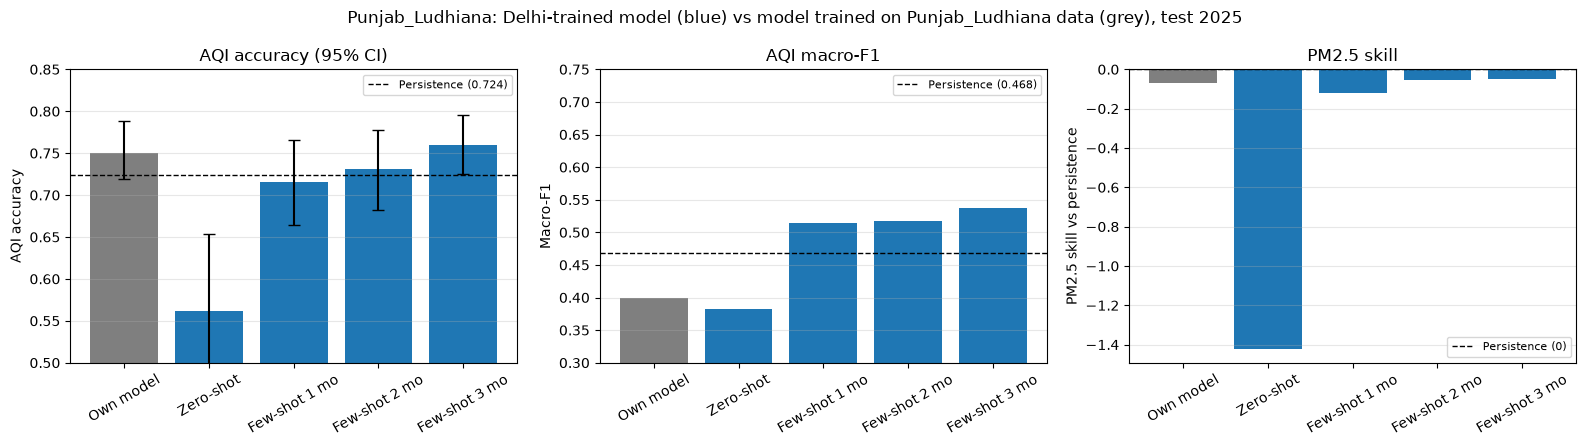

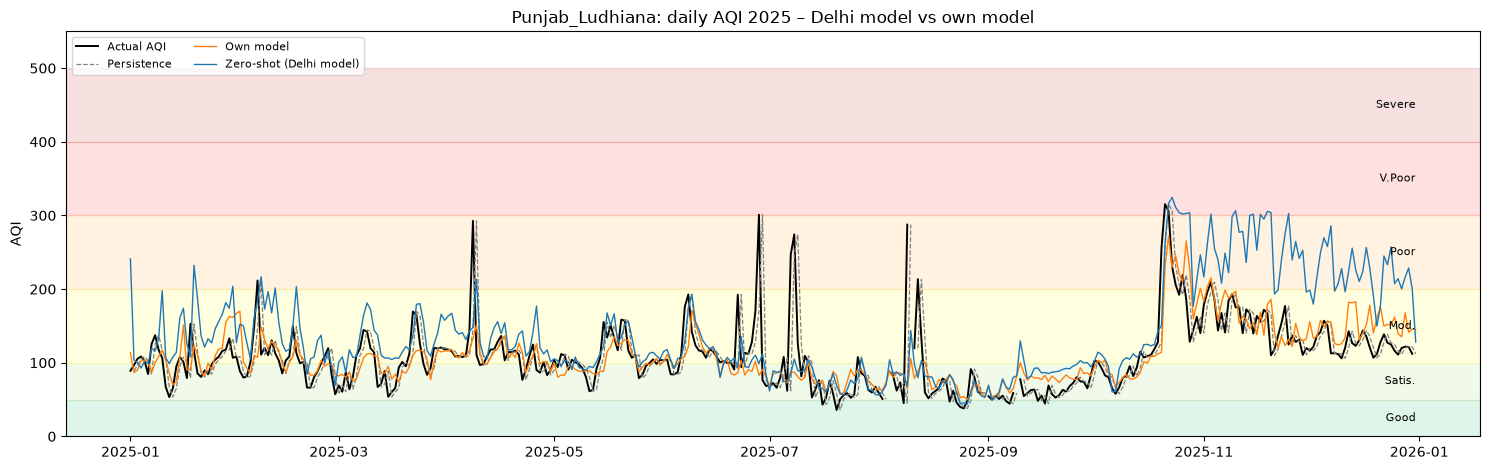

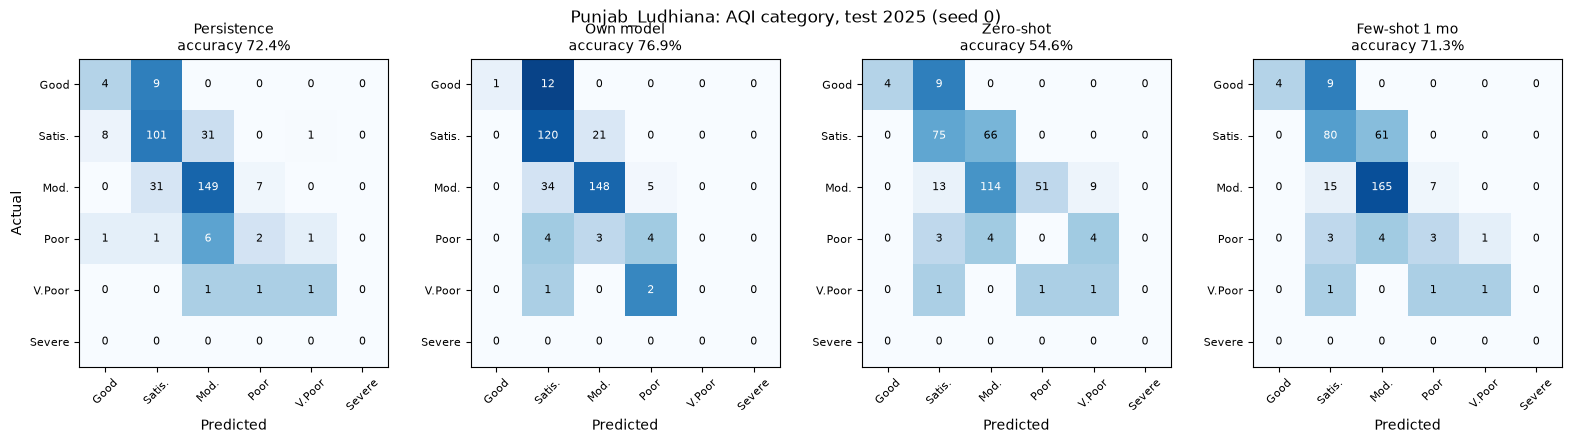

In [21]:
# ===== ITO – Part G plots: transferred model vs own model =====
from sklearn.metrics import confusion_matrix

SHORT   = ["Good", "Satis.", "Mod.", "Poor", "V.Poor", "Severe"]
BANDS   = [0, 50, 100, 200, 300, 400, 500]
COLOURS = ["#00b050", "#92d050", "#ffff00", "#ff9900", "#ff0000", "#c00000"]

def plot_transfer(station, setups, table, Y, pers, pols, test, fig_dir, own_key, zero_key):
    names = list(setups.keys())
    short = ["Own model" if n == own_key else n.replace("Few-shot: Delhi + ", "Few-shot ").replace(" of ITO", "")
             .replace(" month(s)", " mo").replace("Zero-shot (Delhi only)", "Zero-shot") for n in names]
    t = table.set_index("setup")
    pers_acc, pers_f1 = t.loc["Persistence", "accuracy"], t.loc["Persistence", "macro_F1"]
    bar_col = ["#7f7f7f" if n == own_key else "#1f77b4" for n in names]

    # ---- 1. scores by setup ----
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    acc = [t.loc[n, "accuracy"] for n in names]
    ci  = [tuple(map(float, t.loc[n, "acc_gain_95CI"].strip("[]").split(","))) for n in names]
    err = np.array([[a - (pers_acc + lo), (pers_acc + hi) - a] for a, (lo, hi) in zip(acc, ci)]).T
    axes[0].bar(short, acc, color=bar_col, yerr=err, capsize=4)
    axes[0].axhline(pers_acc, color="black", ls="--", lw=1, label=f"Persistence ({pers_acc:.3f})")
    axes[0].set_ylim(0.5, 0.85); axes[0].set_ylabel("AQI accuracy"); axes[0].set_title("AQI accuracy (95% CI)")
    axes[1].bar(short, [t.loc[n, "macro_F1"] for n in names], color=bar_col)
    axes[1].axhline(pers_f1, color="black", ls="--", lw=1, label=f"Persistence ({pers_f1:.3f})")
    axes[1].set_ylim(0.3, 0.75); axes[1].set_ylabel("Macro-F1"); axes[1].set_title("AQI macro-F1")
    axes[2].bar(short, [t.loc[n, "PM2.5_skill"] for n in names], color=bar_col)
    axes[2].axhline(0, color="black", ls="--", lw=1, label="Persistence (0)")
    axes[2].set_ylabel("PM2.5 skill vs persistence"); axes[2].set_title("PM2.5 skill")
    for ax in axes:
        ax.tick_params(axis="x", rotation=30); ax.grid(alpha=0.3, axis="y"); ax.legend(fontsize=8)
    plt.suptitle(f"{station}: Delhi-trained model (blue) vs model trained on {station} data (grey), test 2025")
    plt.tight_layout(); plt.savefig(f"{fig_dir}/transfer_scores.png", dpi=300); plt.show()

    # ---- 2. AQI over 2025 ----
    a_true = U.compute_aqi(Y, pols)
    fig, ax = plt.subplots(figsize=(15, 4.8))
    d = Y.index[test]
    for lo, hi, c, lab in zip(BANDS[:-1], BANDS[1:], COLOURS, SHORT):
        ax.axhspan(lo, hi, color=c, alpha=0.12)
        ax.text(d[-1], (lo + hi) / 2, lab, fontsize=8, va="center", ha="right")
    ax.plot(a_true[test].asfreq("D"), color="black", lw=1.4, label="Actual AQI")
    ax.plot(U.compute_aqi(pers, pols)[test].asfreq("D"), color="grey", lw=0.9, ls="--", label="Persistence")
    ax.plot(U.compute_aqi(setups[own_key][0], pols)[test].asfreq("D"), color="tab:orange", lw=1, label="Own model")
    ax.plot(U.compute_aqi(setups[zero_key][0], pols)[test].asfreq("D"), color="tab:blue", lw=1, label="Zero-shot (Delhi model)")
    ax.set_ylim(0, 550); ax.set_ylabel("AQI"); ax.legend(fontsize=8, loc="upper left", ncol=2)
    ax.set_title(f"{station}: daily AQI 2025 – Delhi model vs own model")
    plt.tight_layout(); plt.savefig(f"{fig_dir}/transfer_aqi_2025.png", dpi=300); plt.show()

    # ---- 3. confusion matrices ----
    show = {"Persistence": pers, "Own model": setups[own_key][0],
            "Zero-shot": setups[zero_key][0], "Few-shot 1 mo": setups[names[2]][0]}
    a_all = {k: U.compute_aqi(v, pols) for k, v in show.items()}
    ok = test & a_true.notna()
    for a in a_all.values():
        ok &= a.notna()
    code = {c: i for i, c in enumerate(U.CATS)}
    yt = U.to_cat(a_true[ok]).map(code).values
    fig, axes = plt.subplots(1, len(show), figsize=(4 * len(show), 4.2))
    for ax, (name, a) in zip(axes, a_all.items()):
        yp = U.to_cat(a[ok]).map(code).values
        cm = confusion_matrix(yt, yp, labels=range(6))
        pct = cm / cm.sum(axis=1, keepdims=True).clip(min=1) * 100
        ax.imshow(pct, cmap="Blues", vmin=0, vmax=100)
        for i in range(6):
            for j in range(6):
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8, color="white" if pct[i, j] > 50 else "black")
        ax.set_title(f"{name}\naccuracy {(yt == yp).mean():.1%}", fontsize=10)
        ax.set_xticks(range(6)); ax.set_xticklabels(SHORT, rotation=45, fontsize=8)
        ax.set_yticks(range(6)); ax.set_yticklabels(SHORT, fontsize=8); ax.set_xlabel("Predicted")
    axes[0].set_ylabel("Actual")
    plt.suptitle(f"{station}: AQI category, test 2025 (seed 0)")
    plt.tight_layout(); plt.savefig(f"{fig_dir}/transfer_confusion.png", dpi=300); plt.show()

plot_transfer(STATION, setups, transfer_ito, Y, pers, POLS_T, test, FIG,
              own_key="Own ITO model (ITO 2023–24)", zero_key="Zero-shot (Delhi only)")

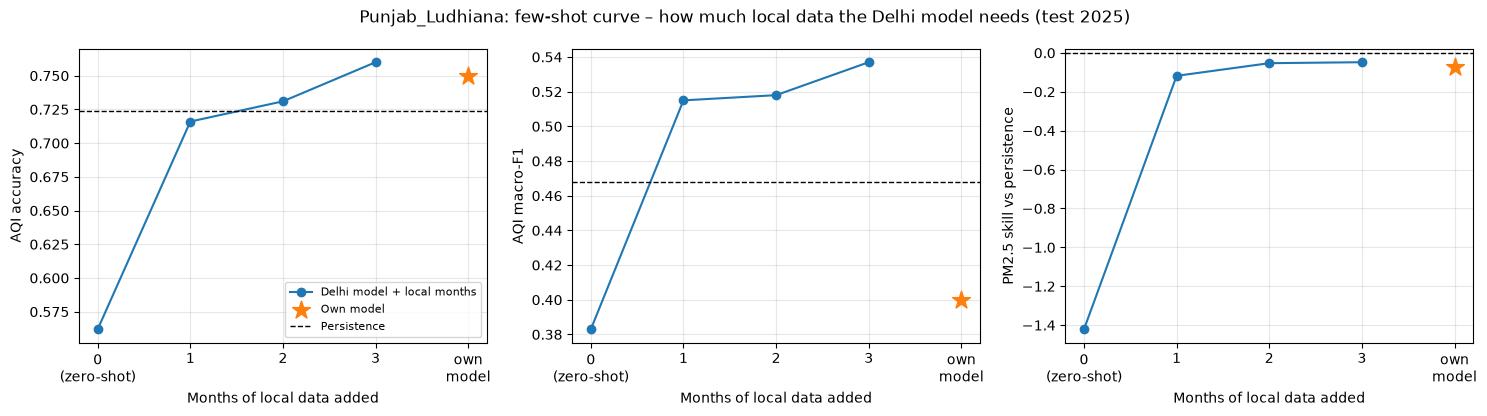

In [22]:
# ===== ITO – Part G plot: few-shot curve (0 -> 1 -> 2 -> 3 months of local data) =====
def plot_fewshot(station, table, zero_key, few_keys, own_key, fig_dir):
    t = table.set_index("setup")
    steps = [zero_key] + few_keys
    x = [0, 1, 2, 3]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
    for ax, (col, lab, base) in zip(axes, [("accuracy", "AQI accuracy", t.loc["Persistence", "accuracy"]),
                                           ("macro_F1", "AQI macro-F1", t.loc["Persistence", "macro_F1"]),
                                           ("PM2.5_skill", "PM2.5 skill vs persistence", 0)]):
        ax.plot(x, [t.loc[s, col] for s in steps], marker="o", color="tab:blue", label="Delhi model + local months")
        ax.scatter([4], [t.loc[own_key, col]], marker="*", s=180, color="tab:orange", zorder=5, label="Own model")
        ax.axhline(base, color="black", ls="--", lw=1, label="Persistence")
        ax.set_xticks([0, 1, 2, 3, 4]); ax.set_xticklabels(["0\n(zero-shot)", "1", "2", "3", "own\nmodel"])
        ax.set_xlabel("Months of local data added"); ax.set_ylabel(lab); ax.grid(alpha=0.3)
    axes[0].legend(fontsize=8)
    plt.suptitle(f"{station}: few-shot curve – how much local data the Delhi model needs (test 2025)")
    plt.tight_layout(); plt.savefig(f"{fig_dir}/fewshot_curve.png", dpi=300); plt.show()

plot_fewshot(STATION, transfer_ito,
             zero_key="Zero-shot (Delhi only)",
             few_keys=["Few-shot: Delhi + 1 month(s) of ITO",
                       "Few-shot: Delhi + 2 month(s) of ITO",
                       "Few-shot: Delhi + 3 month(s) of ITO"],
             own_key="Own ITO model (ITO 2023–24)",
             fig_dir=FIG)

In [23]:
pd.DataFrame({name: U.skill_per_pollutant(preds[0], test, Y, pers, POLS_T)
              for name, preds in setups.items()}).T

,PM2.5,PM10,SO2,CO
Own ITO model (ITO 2023–24),-0.08,-0.06,0.22,-0.17
Zero-shot (Delhi only),-1.52,-0.49,0.17,-0.31
Few-shot: Delhi + 1 month(s) of ITO,-0.12,-0.38,0.26,-0.30
Few-shot: Delhi + 2 month(s) of ITO,-0.08,-0.24,0.26,-0.35
Few-shot: Delhi + 3 month(s) of ITO,-0.04,-0.09,0.26,-0.43


In [24]:
# ===== ITO – Part G (second check): transfer scored on Jan–Sep 2026 =====
rows = [{"setup": "Persistence", **U.scores(pers, test2, Y, pers, POLS_T)}]
for name, preds in setups.items():
    sc = pd.DataFrame([U.scores(p, test2, Y, pers, POLS_T) for p in preds])
    ci = U.gain_ci(preds, test2, Y, pers, POLS_T)
    rows.append({"setup": name, "days": sc.days.iloc[0],
                 "accuracy": round(sc.accuracy.mean(), 3), "macro_F1": round(sc.macro_F1.mean(), 3),
                 "PM2.5_skill": round(sc["PM2.5_skill"].mean(), 3), "PM10_skill": round(sc["PM10_skill"].mean(), 3),
                 "acc_gain_95CI": ci["acc_gain_95CI"], "F1_gain_95CI": ci["F1_gain_95CI"]})
transfer_ito_2026 = pd.DataFrame(rows)
print(f"Transfer Delhi -> {STATION}, test Jan–Sep 2026 (models trained up to Dec 2024):")
print(transfer_ito_2026.to_string(index=False))

# same check at R K Puram for 2026 (5 shared pollutants)
d_test2 = U.in_period(Xd.index, "test2")
sc = pd.DataFrame([U.scores(p, d_test2, Yd, pers_d, POLS_T) for p in d5])
ci = U.gain_ci(d5, d_test2, Yd, pers_d, POLS_T)
print(f"\nCheck – R K Puram Jan–Sep 2026, 5 shared pollutants: persistence acc "
      f"{U.scores(pers_d, d_test2, Yd, pers_d, POLS_T)['accuracy']} | model acc {sc.accuracy.mean():.3f} | "
      f"acc gain {ci['acc_gain']:+.3f} {ci['acc_gain_95CI']} | PM2.5 skill {sc['PM2.5_skill'].mean():.3f}")

Transfer Delhi -> Punjab_Ludhiana, test Jan–Sep 2026 (models trained up to Dec 2024):
                              setup  days  accuracy  macro_F1  PM2.5_skill  PM10_skill    acc_gain_95CI     F1_gain_95CI
                        Persistence   234     0.748     0.498        0.000       0.000              NaN              NaN
        Own ITO model (ITO 2023–24)   234     0.772     0.438       -0.534      -0.284 [-0.026, +0.064] [-0.163, +0.057]
             Zero-shot (Delhi only)   234     0.621     0.311       -3.530      -1.479 [-0.214, -0.059] [-0.398, -0.155]
Few-shot: Delhi + 1 month(s) of ITO   234     0.672     0.444       -1.230      -1.341 [-0.157, -0.010] [-0.152, -0.018]
Few-shot: Delhi + 2 month(s) of ITO   234     0.670     0.443       -0.907      -1.066 [-0.153, -0.019] [-0.148, -0.021]
Few-shot: Delhi + 3 month(s) of ITO   234     0.732     0.489       -0.743      -0.460 [-0.072, +0.027] [-0.066, +0.026]

Check – R K Puram Jan–Sep 2026, 5 shared pollutants: persistence a

In [25]:
# ===== ITO – why does the Delhi model work as well as ITO's own? =====
# 1. how similar are R K Puram and ITO, day by day (2023–2025)?
common_days = Y.index.intersection(Yd.index)
common_days = common_days[(common_days >= "2023-01-01") & (common_days <= "2025-12-31")]
print("Day-to-day correlation, R K Puram vs ITO:")
for p in POLS_T:
    print(f"  {p}: {Yd.loc[common_days, p].corr(Y.loc[common_days, p]):.2f}")

# 2. zero-shot vs own ITO model, directly (own model used as the baseline)
own0 = setups["Own ITO model (ITO 2023–24)"][0]
for label, days in [("2025", test), ("Jan–Sep 2026", test2)]:
    c = U.gain_ci(setups["Zero-shot (Delhi only)"], days, Y, own0, POLS_T)
    print(f"\nZero-shot minus own ITO model, {label}: accuracy {c['acc_gain']:+.3f} {c['acc_gain_95CI']} | "
          f"macro-F1 {c['F1_gain']:+.3f} {c['F1_gain_95CI']}")

Day-to-day correlation, R K Puram vs ITO:
  PM2.5: 0.60
  PM10: 0.65
  SO2: 0.13
  CO: 0.46

Zero-shot minus own ITO model, 2025: accuracy -0.207 [-0.292, -0.121] | macro-F1 -0.038 [-0.195, +0.045]

Zero-shot minus own ITO model, Jan–Sep 2026: accuracy -0.147 [-0.238, -0.068] | macro-F1 -0.073 [-0.409, -0.035]


### At Ludhiana (Punjab, same plain as Delhi, about 300 km), the leakage result repeated (97.7% vs 100%). Without local data, the Delhi model degraded moderately (PM2.5 skill −1.42, far less than at the desert or distant stations), and one month of local data restored accuracy to persistence level. With three months, it exceeded both a locally trained model and persistence (accuracy 76.0% vs 75.0% and 72.4%; macro-F1 0.537 vs 0.400 and 0.468). PM day-to-day variability at Ludhiana fell from 17.9 to 5.2 µg/m³ between the 2023–24 and 2025–26 winters, which suggests a measurement change, so its 2026 results are not used.

In [26]:
# ===== Part I: SHAP top inputs of this station's own model (for the summary table) =====
import shap
rows = []
for p in ["PM2.5", "PM10"]:
    ok = fit & Y[p].notna()
    ttr = U.build_pipeline("ExtraTrees", {**FINAL_PARAMS["ExtraTrees"], "random_state": 0}).fit(X[ok], Y.loc[ok, p])
    pipe = ttr.regressor_
    Xt = X[test & Y[p].notna()]
    Xf = pd.DataFrame(pipe["fill"].transform(Xt), index=Xt.index, columns=X.columns)
    sv = shap.TreeExplainer(pipe["model"]).shap_values(Xf, check_additivity=False)
    share = pd.Series(np.abs(sv).mean(axis=0), index=X.columns)
    share = (share / share.sum() * 100).sort_values(ascending=False).head(8).round(1)
    print(f"\n{STATION} – {p}: top 8 inputs (% of mean |SHAP|)"); print(share)
    rows += [{"station": STATION, "target": p, "rank": i + 1, "input": k, "share_%": v}
             for i, (k, v) in enumerate(share.items())]
pd.DataFrame(rows).to_csv(f"{SUMMARY_DIR}/shap_{STATION}.csv", index=False)


Punjab_Ludhiana – PM2.5: top 8 inputs (% of mean |SHAP|)
PM2.5_lag1     21.6
doy_cos        13.1
PM2.5_mean7    10.8
PM10_lag1      10.4
RF              4.6
WD_cos          4.0
PM10_mean7      3.9
RH              3.8
dtype: float64

Punjab_Ludhiana – PM10: top 8 inputs (% of mean |SHAP|)
PM10_lag1      24.3
PM10_mean7     14.4
PM2.5_lag1     10.3
doy_cos         6.3
RF              5.2
PM2.5_mean7     4.1
RH              3.5
WD_cos          3.3
dtype: float64


In [27]:
a = aqi_true[test].dropna()
print(f"Days within ±15 of AQI 100: {((a - 100).abs() <= 15).mean():.0%} of 2025")

Days within ±15 of AQI 100: 32% of 2025


In [28]:
test_early = (X.index >= "2025-01-01") & (X.index <= "2025-09-30")
for name, preds in setups.items():
    sc = pd.DataFrame([U.scores(p, test_early, Y, pers, POLS_T) for p in preds])
    print(f"{name:40s} acc {sc.accuracy.mean():.3f} | F1 {sc.macro_F1.mean():.3f} | PM2.5 skill {sc['PM2.5_skill'].mean():.3f}")
print("Persistence", U.scores(pers, test_early, Y, pers, POLS_T))

Own ITO model (ITO 2023–24)              acc 0.713 | F1 0.312 | PM2.5 skill 0.029
Zero-shot (Delhi only)                   acc 0.646 | F1 0.360 | PM2.5 skill -0.574
Few-shot: Delhi + 1 month(s) of ITO      acc 0.682 | F1 0.373 | PM2.5 skill -0.057
Few-shot: Delhi + 2 month(s) of ITO      acc 0.696 | F1 0.379 | PM2.5 skill -0.015
Few-shot: Delhi + 3 month(s) of ITO      acc 0.727 | F1 0.393 | PM2.5 skill -0.001
Persistence {'days': 264, 'accuracy': 0.67, 'macro_F1': 0.379, 'PM2.5_skill': 0.0, 'PM10_skill': 0.0}


In [29]:
Y.to_csv(f"{SUMMARY_DIR}/daily_{STATION}.csv")
transfer_table.to_csv(f"{SUMMARY_DIR}/transfer_{STATION}.csv", index=False)

In [31]:
X.to_csv(f"{SUMMARY_DIR}/X_{STATION}.csv")

In [35]:
# valid daily values (%) after QC: day counts if >= 16 valid hours
SEVEN = ["PM2.5", "PM10", "NO2", "SO2", "NH3", "CO", "OZONE"]
have = [p for p in SEVEN if p in data.columns]
print("not in data:", [p for p in SEVEN if p not in have])

days = pd.date_range("2023-01-01", "2026-09-30", freq="D")
valid_hours = data[have].notna().resample("D").sum().reindex(days, fill_value=0)
print(((valid_hours >= 16).mean() * 100).round(1))

not in data: ['NO2', 'NH3', 'OZONE']
PM2.5    96.6
PM10     96.1
SO2      96.7
CO       94.0
dtype: float64
